# Post Feature Creation Analysis
This notebook only ever sees the train data since it is used to understand relationships between the features and the target. It is largely an exploratory step to augment understanding of what features are likely to be good predictors. Features will not be dropped solely on the basis of results found here, since all selected models are regularized or capable of feature selection in their own ways.

In [30]:
import numpy as np
import pandas as pd

from feature_engineering import get_data
from constants import FEATURES, NUMERIC, ORDINAL, CATEGORICAL, BINARY

pd.set_option("display.max_columns", 50)

In [15]:
data = get_data()
X = data["X_train"]
y = data["y_train"]
del data
# test data is not used anywhere

print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (800, 21) | y shape: (800,)


In [16]:
# 1. Feature set matches the plan
groups = NUMERIC + ORDINAL + CATEGORICAL + BINARY
assert set(groups) == set(X.columns) == set(FEATURES)
assert X.index.equals(y.index), "X and y index mismatch"
print("Feature groups OK:", len(groups), "features")

# 2. Class balance (expect about 30% default)
print("\nTrain default rate:", round(y.mean(), 4))
print(y.value_counts().rename({0: "good", 1: "bad"}))

# 3. Missing values and infinities
missing = X.isna().sum()
print("\nColumns with missing values:\n", missing[missing > 0] if missing.any() else "none")
num_cols = NUMERIC + ORDINAL + BINARY
inf_counts = np.isinf(X[num_cols]).sum()
print("Columns with infinities:\n", inf_counts[inf_counts > 0] if inf_counts.any() else "none")

# 4. Types and duplicates
print("\nDtypes:\n", X.dtypes.value_counts())
print("Duplicate rows:", X.duplicated().sum())

Feature groups OK: 21 features

Train default rate: 0.3
default
good    560
bad     240
Name: count, dtype: int64

Columns with missing values:
 none
Columns with infinities:
 none

Dtypes:
 int64      12
str         6
float64     3
Name: count, dtype: int64
Duplicate rows: 0


### Numerical Features
To explore the numerical/continuous features, we:
1. Plot box plots for the two target values (to see if there are differences in distribution)
2. Plot a correlation heatmap and find the VIFs of all the predictors to check for multicollinearity. Variables need not necessarily be dropped due to this due to the model selection.
3. Bin the variables and find the Information Value. This is standard practice in the credit industry to test the power of a predictor. However, with our sample size of 800, the IV estimates may be unstable. To address this, bootstrapping is performed to get a 95% CI for the IV instead of a point estimate.

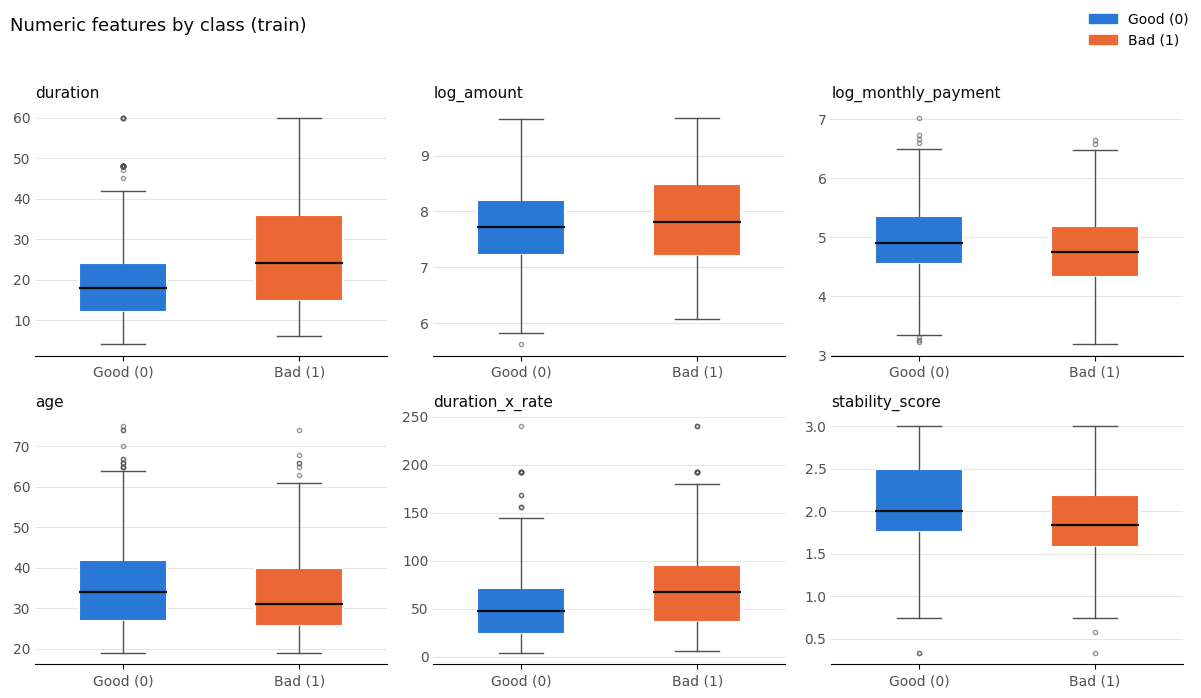

In [17]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

GOOD, BAD = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), NUMERIC):
    groups = [X.loc[y == 0, col], X.loc[y == 1, col]]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.5,
                    medianprops=dict(color=INK, linewidth=1.6),
                    whiskerprops=dict(color=MUTED, linewidth=1),
                    capprops=dict(color=MUTED, linewidth=1),
                    flierprops=dict(marker="o", markersize=3, markerfacecolor="none",
                                    markeredgecolor=MUTED, alpha=0.6))
    for box, colour in zip(bp["boxes"], [GOOD, BAD]):
        box.set(facecolor=colour, edgecolor="white", linewidth=1.5)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Good (0)", "Bad (1)"], color=MUTED)
    ax.set_title(col, color=INK, fontsize=11, loc="left")
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", colors=MUTED, length=0)

fig.legend(handles=[Patch(color=GOOD, label="Good (0)"), Patch(color=BAD, label="Bad (1)")],
           loc="upper right", frameon=False)
fig.suptitle("Numeric features by class (train)", x=0.01, ha="left", color=INK, fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Notes:
1. `Duration` and `log_amount` have wider distributions for the `bad` values and slightly higher medians.
2. `Stability_score` and `duration_x_rate` show clear difference in median, adding evidence to the value of these engineered variables.
3. Ordinal variables are not included here since boxplots are far less informative when the possible values are limited. They will be covered in the categorical sections.

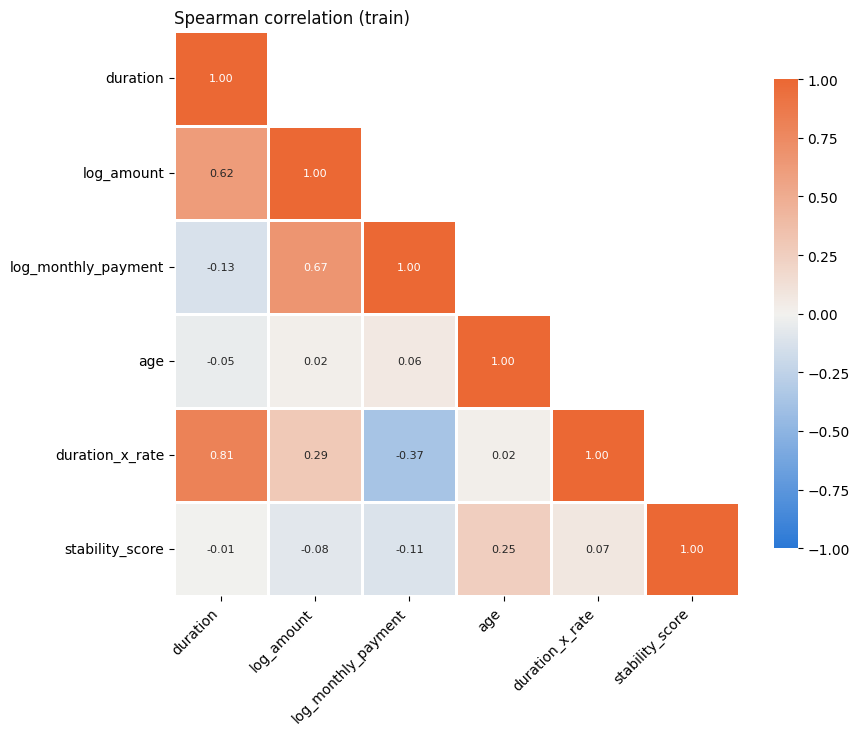

rho  abs_rho
duration_x_rate     duration             0.807    0.807
log_monthly_payment log_amount           0.666    0.666
log_amount          duration             0.622    0.622
duration_x_rate     log_monthly_payment -0.374    0.374
                    log_amount           0.290    0.290
stability_score     age                  0.253    0.253
log_monthly_payment duration            -0.125    0.125
stability_score     log_monthly_payment -0.111    0.111
                    log_amount          -0.081    0.081
                    duration_x_rate      0.074    0.074

In [18]:
import seaborn as sns

cols = NUMERIC
corr = X[cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the upper triangle
cmap = LinearSegmentedColormap.from_list("div", [GOOD, "#f2f1ee", BAD])

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=1, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation (train)", loc="left", color=INK)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# strongest pairs, for reading off quickly
pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack().rename("rho").to_frame()
pairs["abs_rho"] = pairs["rho"].abs()
display(pairs.sort_values("abs_rho", ascending=False).head(10).round(3))

In [19]:
def compute_vif(df):
    out = {}
    for col in df.columns:
        target = df[col].values.astype(float)
        others = np.column_stack([np.ones(len(df)), df.drop(columns=col).values.astype(float)])
        beta, *_ = np.linalg.lstsq(others, target, rcond=None)
        r_squared = 1 - (target - others @ beta).var() / target.var()
        out[col] = 1 / (1 - r_squared)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

vif = compute_vif(X[NUMERIC])
display(vif.round(2).to_frame())

,VIF
log_amount,18.61
duration,12.43
log_monthly_payment,11.31
duration_x_rate,3.49
age,1.09
stability_score,1.08


Notes:
1. There is very clear multicollinearity which is expected since the numerical variables are derived from one another.
2. Variables are not dropped here since the models are regularized or capable of feature selection and therefore, will be able to find the most informative feature of the multicollinear ones.


duration  (IV = 0.213)


,good,bad,bad_rate,woe,iv_term
duration,,,,,
"(3.999, 12.0]",229,59,0.205,0.509,0.083
"(12.0, 15.0]",49,11,0.183,0.618,0.025
"(15.0, 24.0]",178,92,0.341,-0.184,0.012
"(24.0, 30.0]",30,14,0.318,-0.098,0.001
"(30.0, 60.0]",74,64,0.464,-0.697,0.093



log_amount  (IV = 0.065)


,good,bad,bad_rate,woe,iv_term
log_amount,,,,,
"(5.619, 7.136]",111,49,0.306,-0.029,0.000
"(7.136, 7.545]",122,38,0.238,0.316,0.019
"(7.545, 7.943]",114,46,0.288,0.060,0.001
"(7.943, 8.44]",117,43,0.269,0.152,0.004
"(8.44, 9.677]",96,64,0.400,-0.439,0.041



log_monthly_payment  (IV = 0.073)


,good,bad,bad_rate,woe,iv_term
log_monthly_payment,,,,,
"(3.1790000000000003, 4.37]",95,65,0.406,-0.464,0.047
"(4.37, 4.711]",111,49,0.306,-0.029,0.000
"(4.711, 5.028]",114,46,0.288,0.060,0.001
"(5.028, 5.431]",122,38,0.238,0.316,0.019
"(5.431, 7.027]",118,42,0.262,0.184,0.007


... (3 outputs left out)

,good,bad,bad_rate,woe,iv_term
duration_x_rate,,,,,
"(3.999, 24.0]",154,33,0.176,0.687,0.094
"(24.0, 48.0]",165,74,0.310,-0.043,0.001
"(48.0, 60.0]",48,12,0.200,0.514,0.018
"(60.0, 96.0]",134,67,0.333,-0.152,0.006
"(96.0, 240.0]",59,54,0.478,-0.754,0.090



stability_score  (IV = 0.097)


,good,bad,bad_rate,woe,iv_term
stability_score,,,,,
"(0.332, 1.583]",118,68,0.366,-0.293,0.021
"(1.583, 1.833]",121,53,0.305,-0.021,0.000
"(1.833, 2.083]",79,46,0.368,-0.305,0.015
"(2.083, 2.5]",144,51,0.262,0.190,0.008
"(2.5, 3.0]",98,22,0.183,0.635,0.052


,point_iv,boot_median,ci_low,ci_high
duration,0.213,0.231,0.117,0.413
duration_x_rate,0.208,0.215,0.104,0.382
stability_score,0.097,0.121,0.043,0.259
log_monthly_payment,0.073,0.090,0.024,0.188
log_amount,0.065,0.085,0.027,0.205
age,0.043,0.065,0.018,0.173


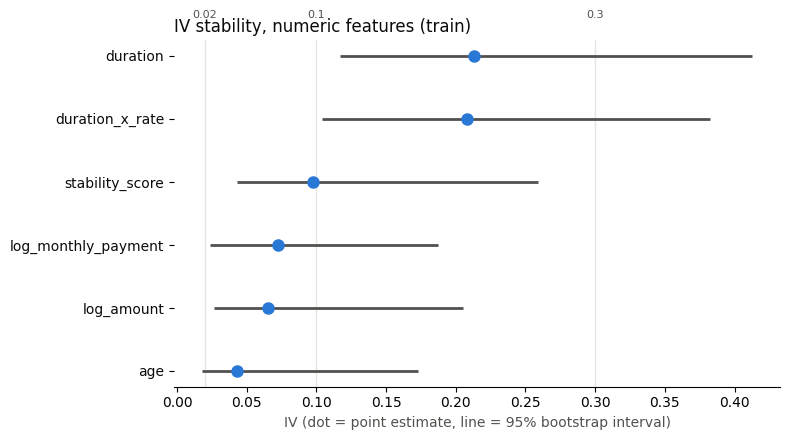

In [20]:
from constants import SEED

def iv_table(x, y, n_bins=5, smooth=0.5):
    """Quantile bin x, then return counts, bad rate, WoE and IV contribution per bin."""
    bins = pd.qcut(x, q=n_bins, duplicates="drop")
    counts = pd.crosstab(bins, y).reindex(columns=[0, 1], fill_value=0)
    counts.columns = ["good", "bad"]
    out = counts.copy()
    out["bad_rate"] = counts["bad"] / (counts["good"] + counts["bad"])
    smoothed = counts + smooth                                   # avoids ln(0) in empty cells
    pct_good = smoothed["good"] / smoothed["good"].sum()
    pct_bad = smoothed["bad"] / smoothed["bad"].sum()
    out["woe"] = np.log(pct_good / pct_bad)
    out["iv_term"] = (pct_good - pct_bad) * out["woe"]
    return out

tables = {col: iv_table(X[col], y) for col in NUMERIC}
point_iv = pd.Series({col: t["iv_term"].sum() for col, t in tables.items()}, name="point_iv")

for col, t in tables.items():
    print(f"\n{col}  (IV = {t['iv_term'].sum():.3f})")
    display(t.round(3))



def iv_fast(x, y, n_bins=5, smooth=0.5):
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)[1:-1]))
    bin_id = np.searchsorted(edges, x, side="left")
    k = len(edges) + 1
    good = np.bincount(bin_id[y == 0], minlength=k)
    bad = np.bincount(bin_id[y == 1], minlength=k)
    keep = (good + bad) > 0
    good, bad = good[keep] + smooth, bad[keep] + smooth
    pct_good, pct_bad = good / good.sum(), bad / bad.sum()
    return np.sum((pct_good - pct_bad) * np.log(pct_good / pct_bad))

# check it agrees with the pandas version before trusting it
for col in NUMERIC:
    assert np.isclose(iv_fast(X[col].to_numpy(), y.to_numpy()), point_iv[col]), col

n_boot = 500
rng = np.random.default_rng(SEED)
Xv, yv = X[NUMERIC].to_numpy(), y.to_numpy()
n = len(yv)

boot = np.empty((n_boot, len(NUMERIC)))
for b in range(n_boot):
    pick = rng.integers(0, n, size=n)
    for j in range(len(NUMERIC)):
        boot[b, j] = iv_fast(Xv[pick, j], yv[pick])

summary = pd.DataFrame({
    "point_iv": point_iv,
    "boot_median": np.median(boot, axis=0),
    "ci_low": np.percentile(boot, 2.5, axis=0),
    "ci_high": np.percentile(boot, 97.5, axis=0),
}, index=NUMERIC).sort_values("point_iv", ascending=False)
display(summary.round(3))


order = summary.sort_values("point_iv").index
ypos = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(ypos, summary.loc[order, "ci_low"], summary.loc[order, "ci_high"],
          color=MUTED, linewidth=2)
ax.plot(summary.loc[order, "point_iv"], ypos, "o", color=GOOD, markersize=8)
for cutoff in (0.02, 0.1, 0.3):
    ax.axvline(cutoff, color=GRID, linewidth=1, zorder=0)
    ax.text(cutoff, len(order) - 0.4, f"{cutoff}", color=MUTED, fontsize=8, ha="center")
ax.set_yticks(ypos)
ax.set_yticklabels(order, color=INK)
ax.set_xlabel("IV (dot = point estimate, line = 95% bootstrap interval)", color=MUTED)
ax.set_title("IV stability, numeric features (train)", loc="left", color=INK)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

Notes:
1. The vertical bands represent the standard cutoffs for the IV: above 0.3 is strong, above 0.1 is medium and lower than that is weak.
2. Looking at our CIs, `duration` and `duration_x_rate` are medium to strong predictors and will likely improve models.
3. `stability_score` point estimate sits right at the threshold for medium with a larger part of the interval in the medium range. The rest are all weak to medium predictors.

### Categorical variables
To study the categorical (and ordinal) variables, we:\
1. Tabulate the bad rate percetange per category
2. Find the IV for each variable. Once again, due to the limited sample, we bootstrap and attain the CIs.

In [21]:
def bad_rate_table(col, sort_by_rate=False):
    t = y.groupby(X[col]).agg(n="size", bads="sum")
    t["bad_rate"] = t["bads"] / t["n"]
    return t.sort_values("bad_rate", ascending=False) if sort_by_rate else t.sort_index()

print(f"Overall train bad rate: {y.mean():.3f}")

groups_to_show = [
    ("NOMINAL CATEGORICAL (sorted by bad rate)", CATEGORICAL, True),
    ("ORDINAL (sorted by level)", ORDINAL, False),
    ("BINARY", BINARY, False),
]
for title, cols, by_rate in groups_to_show:
    print(f"\n{'=' * 8} {title} {'=' * 8}")
    for col in cols:
        print(f"\n{col}")
        display(bad_rate_table(col, sort_by_rate=by_rate).round(3))

Overall train bad rate: 0.300

======== NOMINAL CATEGORICAL (sorted by bad rate) ========

checking


,n,bads,bad_rate
checking,,,
<0,219,105,0.479
0-200,214,84,0.393
>=200,51,13,0.255
none,316,38,0.120



savings


,n,bads,bad_rate
savings,,,
<100,475,173,0.364
100-500,90,30,0.333
unknown/none,144,24,0.167
500-1000,50,8,0.160
>=1000,41,5,0.122



history


,n,bads,bad_rate
history,,,
none/all paid,31,19,0.613
all paid (this bank),41,22,0.537
existing paid,416,134,0.322
past delay,72,23,0.319
critical,240,42,0.175


... (20 outputs left out)


has_coapplicant


,n,bads,bad_rate
has_coapplicant,,,
0,766,225,0.294
1,34,15,0.441



thin_buffer


,n,bads,bad_rate
thin_buffer,,,
0,625,151,0.242
1,175,89,0.509


Notes:
1. For the categorical variables, there are clear categories where the bad rate is much higher. This is especially visible in `checking`, `housing_type`, `saving` and `purpose_type`. 
2. For the ordinal variables, the expected ordering is maintained in all except one, `employment_level`
3. For the binary variables, there is clear separation, especially in `thin_buffer` which is likely to be a strong predictor.

,group,point_iv,boot_median,ci_low,ci_high
checking,categorical,0.609,0.623,0.413,0.878
history,categorical,0.262,0.275,0.151,0.460
thin_buffer,binary,0.255,0.252,0.130,0.438
asset_score,ordinal,0.228,0.239,0.115,0.416
savings,categorical,0.214,0.236,0.118,0.414
property_level,ordinal,0.145,0.160,0.062,0.327
employment_level,ordinal,0.124,0.140,0.058,0.271
other_plans,categorical,0.091,0.095,0.025,0.208
housing,categorical,0.089,0.091,0.024,0.202
purpose_type,categorical,0.074,0.086,0.026,0.201


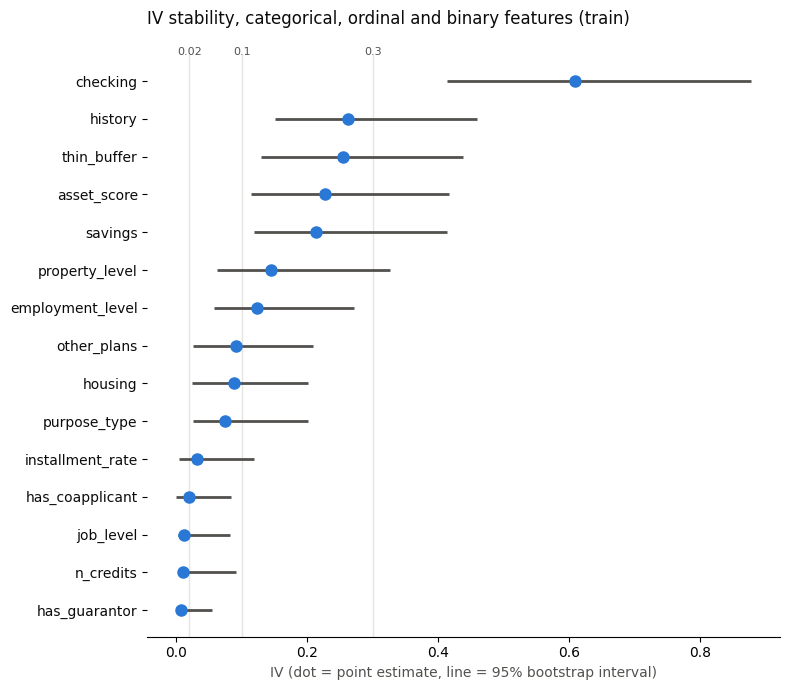

In [22]:
CAT_ALL = CATEGORICAL + ORDINAL + BINARY
yv = y.to_numpy()
n = len(yv)

# one integer id per (level, class) cell: level code * 2 + y, built once
cell, n_levels = {}, {}
for col in CAT_ALL:
    codes, uniques = pd.factorize(X[col])
    cell[col] = codes * 2 + yv
    n_levels[col] = len(uniques)

def iv_from_cells(cell_ids, k, smooth=0.5):
    joint = np.bincount(cell_ids, minlength=2 * k).reshape(k, 2)   # columns: good, bad
    joint = joint[joint.sum(axis=1) > 0] + smooth                   # drop empty levels, smooth the rest
    pct_good = joint[:, 0] / joint[:, 0].sum()
    pct_bad = joint[:, 1] / joint[:, 1].sum()
    return np.sum((pct_good - pct_bad) * np.log(pct_good / pct_bad))

# point estimates
cat_point = pd.Series({c: iv_from_cells(cell[c], n_levels[c]) for c in CAT_ALL})

# bootstrap
n_boot = 500
rng = np.random.default_rng(SEED)
cat_boot = np.empty((n_boot, len(CAT_ALL)))
for b in range(n_boot):
    pick = rng.integers(0, n, size=n)                               # rows drawn with replacement
    for j, c in enumerate(CAT_ALL):
        cat_boot[b, j] = iv_from_cells(cell[c][pick], n_levels[c])

group_of = {**{c: "categorical" for c in CATEGORICAL},
            **{c: "ordinal" for c in ORDINAL},
            **{c: "binary" for c in BINARY}}
cat_summary = pd.DataFrame({
    "group": pd.Series(group_of),
    "point_iv": cat_point,
    "boot_median": np.median(cat_boot, axis=0),
    "ci_low": np.percentile(cat_boot, 2.5, axis=0),
    "ci_high": np.percentile(cat_boot, 97.5, axis=0),
}, index=CAT_ALL).sort_values("point_iv", ascending=False)
display(cat_summary.round(3))

# plot
order = cat_summary.sort_values("point_iv").index
ypos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 7))
ax.hlines(ypos, cat_summary.loc[order, "ci_low"], cat_summary.loc[order, "ci_high"],
          color=MUTED, linewidth=2)
ax.plot(cat_summary.loc[order, "point_iv"], ypos, "o", color=GOOD, markersize=8)
for cutoff in (0.02, 0.1, 0.3):
    ax.axvline(cutoff, color=GRID, linewidth=1, zorder=0)
    ax.text(cutoff, len(order) - 0.3, f"{cutoff}", color=MUTED, fontsize=8, ha="center")
ax.set_yticks(ypos)
ax.set_yticklabels(order, color=INK)
ax.set_xlabel("IV (dot = point estimate, line = 95% bootstrap interval)", color=MUTED)
ax.set_title("IV stability, categorical, ordinal and binary features (train)",
             loc="left", color=INK, pad=22)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

Notes:
1. `checking` has an IV of 0.6 and is most likely the top expected predictor in the models to follow.
2. Several other features, most of which are engineered are also in the medium to strong range and will likely feature.
3. The last few in the graph have point estimates near 0. These are not dropped at this point but are not expected to have any signficant impact.